In [2]:
# ==== Standard imports ====
from __future__ import annotations
import os
import math
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, PercentFormatter
import seaborn as sns
from wordcloud import WordCloud
from matplotlib import cm
from matplotlib.colors import ListedColormap
import re
import geopandas as gpd
from matplotlib.patches import Patch

# ==== Reproducibility ====
os.environ["PYTHONHASHSEED"] = "0"
np.random.seed(42)

# ==== Directories ====
PROJECT_ROOT = Path.cwd()  # adjust if needed
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ==== Visual constants ====
BG = "none"    # transparent background
TXT = "black"  # text color

# ==== Warnings kept quiet (but not all) ====
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")

# ==== Font configuration (prefer Arial; fallback to DejaVu) ====
def _ensure_arial():
    """Prefer Arial; Matplotlib will silently fallback if unavailable."""
    mpl.rcParams["font.family"] = "Arial"

_ensure_arial()

# ==== Global style ====
mpl.rcParams.update(
    {
        "pdf.fonttype": 42,          # Editable text in PDFs
        "ps.fonttype": 42,
        "figure.dpi": 150,           # Notebook preview; export uses 300 dpi below
        "savefig.dpi": 300,          # Ensures 300 dpi on save
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "axes.grid": True,
        "grid.linestyle": "--",
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.autolayout": False,  # we call tight_layout() explicitly
    }
)

# Seaborn baseline with your palette
sns.set_theme(context="paper", style="whitegrid", palette="YlOrBr")

# ==== Utility Functions ====
def savefig_pdf(fig: mpl.figure.Figure, filename: str, subdir: Path | None = None) -> Path:
    """
    Save figure as PDF at 300 dpi with tight layout. Returns the saved path.
    """
    target_dir = FIG_DIR if subdir is None else (FIG_DIR / subdir)
    target_dir.mkdir(parents=True, exist_ok=True)
    path = target_dir / f"{filename}.pdf"
    fig.tight_layout()
    fig.savefig(path, format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": "Jupyter"})
    plt.close(fig)
    return path

def _clean_str_series(s: pd.Series) -> pd.Series:
    """Lower/strip only on strings; preserva NaN."""
    s = s.copy()
    s = s.where(~s.isna(), other=pd.NA)
    s = s.astype("string")
    s = s.str.strip().str.lower()
    return s

def _split_semicolon(series: pd.Series) -> pd.Series:
    """Explode por ';' preservando NaN (que serão removidos antes do explode)."""
    tmp = series.dropna().astype("string").str.split(";")
    return tmp.explode().str.strip()

# ==== Data Loaders ====
def load_selection_table(xlsx_path: str | Path) -> pd.DataFrame:
    """
    Load selection table. Expects columns like:
    ['year', 'country', 'region', 'drought_type', 'model', 'metric'].
    """
    df = pd.read_excel(xlsx_path)
    rename_map = {
        "Year": "year",
        "Country": "country",
        "Region": "region",
        "DroughtType": "drought_type",
        "Model": "model",
        "Metric": "metric",
    }
    df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})
    for col in ["country", "region", "drought_type", "model", "metric"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()
    if "year" in df.columns:
        df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
    return df

def load_extraction_table(xlsx_path: str | Path) -> pd.DataFrame:
    """Load final metadata table using the same normalization rules."""
    return load_selection_table(xlsx_path)

# ==== FIG 3 - Temporal Distribution Functions ====
def analyze_year_frequencies(
    path: str | Path,
    sheet_index: int | str = 0,
    year_range: tuple[int, int] = (2015, 2025),
    year_col: str | None = None,
) -> pd.DataFrame:
    """
    Compute annual frequencies within a given range and cumulative (%) series.

    Returns DataFrame with columns:
    ['Year', 'Frequency', 'Cumulative', 'Percentage', 'CumulativePct'].
    """
    df = pd.read_excel(path, sheet_name=sheet_index)

    # Auto-detect year column if not provided
    if year_col is None:
        candidates = [c for c in df.columns if str(c).strip().lower() in {"year", "ano"}]
        if not candidates:
            raise ValueError("No year column found. Use 'Year' or 'Ano'.")
        year_col = candidates[0]

    # Clean and filter
    years = pd.to_numeric(df[year_col], errors="coerce").dropna().astype(int)
    start, end = year_range
    years = years[(years >= start) & (years <= end)]

    # Count + ensure missing years are present
    counts = years.value_counts().sort_index()
    full_index = pd.Index(range(start, end + 1), name="Year")
    counts = counts.reindex(full_index, fill_value=0)

    out = pd.DataFrame({"Year": counts.index, "Frequency": counts.values})
    out["Cumulative"] = out["Frequency"].cumsum()

    total = out["Frequency"].sum()
    if total == 0:
        out["Percentage"] = 0.0
        out["CumulativePct"] = 0.0
    else:
        out["Percentage"] = (out["Frequency"] / total) * 100.0
        out["CumulativePct"] = (out["Cumulative"] / total) * 100.0

    return out

def plot_year_frequency_cumulative_chart(
    df_analysis: pd.DataFrame,
    annotate_bars: bool = False,
    step_y: int | None = None,
) -> mpl.figure.Figure:
    """
    Bar chart (frequency by year) + cumulative line (%) on secondary axis.
    - Palette: YlOrBr for bars
    - Cumulative line: red (#D62728)
    - No title (per manuscript style)
    - Transparent background
    """
    # Font baseline for this figure
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 13

    # Palette for bars; ensure one color per bar (length == #years)
    palette = sns.color_palette("YlOrBr", n_colors=len(df_analysis["Year"].unique()))
    line_color = "#D62728"  # red cumulative line

    fig, ax1 = plt.subplots(figsize=(12, 6), facecolor=BG)
    ax1.set_facecolor(BG)

    # Bars (frequency)
    bars = ax1.bar(
        df_analysis["Year"],
        df_analysis["Frequency"],
        color=palette,
        alpha=0.9,
        label="Frequency",
        width=0.85,
        edgecolor="white",
        linewidth=0.8,
    )

    ax1.set_xlabel("Year", color=TXT)
    ax1.set_ylabel("Frequency", color=TXT)
    ax1.tick_params(axis="both", colors=TXT, labelrotation=45)
    ax1.set_xticks(df_analysis["Year"])
    ax1.grid(True, which="major", axis="y", linestyle=":", linewidth=0.8, alpha=0.4)

    # Y-axis limits and ticks
    max_freq = int(df_analysis["Frequency"].max())
    y_max = max(5, int(math.ceil(max_freq / 5.0) * 5))
    ax1.set_ylim(0, y_max)
    ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
    if step_y:
        ax1.set_yticks(np.arange(0, y_max + 1, step_y))

    # Cumulative line (%)
    ax2 = ax1.twinx()
    ax2.plot(
        df_analysis["Year"],
        df_analysis["CumulativePct"],
        color=line_color,
        linewidth=2.2,
        label="Cumulative (%)",
    )
    nonzero = df_analysis[df_analysis["Frequency"] > 0]
    ax2.scatter(nonzero["Year"], nonzero["CumulativePct"], color=line_color, s=40, zorder=5)
    ax2.set_ylabel("Cumulative (%)", color=TXT)
    ax2.tick_params(axis="y", colors=TXT)
    ax2.yaxis.set_major_formatter(PercentFormatter(xmax=100))
 

    if annotate_bars:
        for i, (x, y) in enumerate(zip(df_analysis["Year"], df_analysis["CumulativePct"])):
            freq = df_analysis.loc[i, "Frequency"]
            if freq > 0:
                ax2.text(
                    x,
                    y + 1.5,  # ligeiramente acima da linha
                    f"{freq}",
                    ha="center",
                    va="bottom",
                    fontsize=10,
                    color="black",  
                    fontweight="bold",
                    zorder=6,
                )


    # Legend (Frequency + Cumulative)
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    leg = ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper left",
        frameon=True,
        facecolor="white",
        framealpha=0.75,
        edgecolor="none",
        prop={"family": "Arial", "size": 12},
    )
    for t in leg.get_texts():
        t.set_color(TXT)

    # Subtle borders
    for spine in ["top", "right", "left", "bottom"]:
        ax1.spines[spine].set_linewidth(0.8)
        ax1.spines[spine].set_edgecolor("#999999")

    # No title (as requested)
    return fig

def plot_publications_per_year(df: pd.DataFrame, year_col: str = "year") -> mpl.figure.Figure:
    """
    Minimal bar chart of publications per year.
    - Palette: YlOrBr
    - No title
    - Transparent background
    """
    data = df.dropna(subset=[year_col]).copy()
    counts = data[year_col].astype(int).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(6.8, 3.4), facecolor=BG)
    ax.set_facecolor(BG)

    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="YlOrBr")
    ax.set_xlabel("Year", color=TXT)
    ax.set_ylabel("Number of studies", color=TXT)
    if len(counts) > 12:
        for label in ax.get_xticklabels():
            label.set_rotation(45)
            label.set_ha("right")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    return fig

# ==== FIG 4 - Citation Analysis Functions ====
def plot_citations_boxplot_by_year(
    df: pd.DataFrame,
    year_col: str = "Year",
    citation_col: str = "Citations",
) -> mpl.figure.Figure:
    """
    Boxplot of citation counts grouped by year.
    - Outliers shown as small circles
    - Medians visible
    - Uses YlOrBr palette
    - Transparent background, no title
    """
    # Font/style
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 13
    sns.set_style("white")

    # Year order
    df = df.copy()
    df[year_col] = df[year_col].astype(int)
    years_order = sorted(df[year_col].unique())

    fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
    ax.set_facecolor(BG)

    palette = sns.color_palette("YlOrBr", len(years_order))

    sns.boxplot(
        x=year_col,
        y=citation_col,
        data=df,
        order=years_order,
        ax=ax,
        palette=palette,
        boxprops=dict(alpha=0.85),
        medianprops=dict(color="black", linewidth=1.5),
        flierprops=dict(marker="o", markersize=4, markerfacecolor="gray", markeredgewidth=0),
    )

    ax.set_xlabel("Year", color=TXT)
    ax.set_ylabel("Citations", color=TXT)
    ax.tick_params(axis="x", rotation=45, colors=TXT)
    ax.tick_params(axis="y", colors=TXT)

    # Grid: horizontal only
    ax.grid(True, which="major", axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.4)
    ax.grid(False, axis="x")

    # Box edges
    for patch in ax.patches:
        patch.set_edgecolor("gray")
        patch.set_linewidth(1)

    # Spines (subtle)
    for spine in ax.spines.values():
        spine.set_edgecolor("gray")
        spine.set_linewidth(1)

    return fig

# ==== FIG 5 - Journal Analysis Functions ====
def analyze_journal_frequencies(
    path: str | Path,
    sheet_index: int | str = 0,
    threshold: int = 3,
) -> pd.DataFrame:
    """
    Count journal frequencies and group low-frequency entries as 'Others'.
    Returns a DataFrame with columns ['Journal', 'Frequency'].
    - 'Others (<threshold)' aggregates all journals with count < threshold.
    - Removes 'IEEE Access' as requested.
    """
    df = pd.read_excel(path, sheet_name=sheet_index)

    if "Journal" not in df.columns:
        raise ValueError("Column 'Journal' not found in the sheet.")

    journal_counts = df["Journal"].value_counts(dropna=False)

    # Select frequent journals and aggregate the rest as 'Others'
    frequent = journal_counts[journal_counts >= threshold]
    others_count = journal_counts[journal_counts < threshold].sum()

    if others_count > 0:
        frequent = pd.concat(
            [frequent, pd.Series({f"Others (<{threshold})": others_count})]
        )

    df_analysis = pd.DataFrame(
        {"Journal": frequent.index.astype(str), "Frequency": frequent.values}
    )

    # Specific removal
    df_analysis = df_analysis[df_analysis["Journal"] != "IEEE Access"].reset_index(drop=True)
    return df_analysis

def plot_journal_bar_chart(
    df_analysis: pd.DataFrame,
) -> mpl.figure.Figure:
    """
    Horizontal bar chart of journal frequencies (YlOrBr).
    - No title
    - Transparent background
    - Percentage labels to the right of each bar
    - Keeps 'Others' as the last row
    """
    # Style and font
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 13
    sns.set_style("white")

    # Abbreviations for long journal names (edit if needed)
    abbreviations = {
        "International Journal of Applied Earth Observation and Geoinformation":
            "Int. J. Appl. Earth Obs. & Geoinfo.",
        "Remote Sensing of Environment":
            "Remote Sens. Environ.",
        "Journal of Hydrology":
            "J. Hydrol.",
        "Earth Science Informatics":
            "Earth Sci. Informatics",
        "Remote Sensing Applications: Society and Environment":
            "Remote Sens. Appl.: Soc. & Environ.",
        "IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing":
            "IEEE J. Sel. Top. Appl. Earth Obs. Remote Sens.",
    }

    df_plot = df_analysis.copy()
    df_plot["Journal"] = df_plot["Journal"].map(lambda x: abbreviations.get(x, x))

    # Ensure "Others" is shown last
    df_plot["is_others"] = df_plot["Journal"].str.startswith("Others")
    # Keep original ordering intent; within groups order by Frequency ascending (as in your version)
    df_plot = df_plot.sort_values(by=["is_others", "Frequency"], ascending=[True, True]).drop(columns="is_others")

    # Palette
    palette = sns.color_palette("YlOrBr", n_colors=len(df_plot))

    # Figure
    fig, ax = plt.subplots(figsize=(11, 6), facecolor=BG)
    ax.set_facecolor(BG)

    bars = ax.barh(
        df_plot["Journal"],
        df_plot["Frequency"],
        color=palette,
        edgecolor="white",
        height=0.7,
        alpha=0.85,
    )

    ax.set_xlabel("Frequency", color=TXT)
    ax.set_ylabel("")
    ax.tick_params(axis="x", colors=TXT)
    ax.tick_params(axis="y", colors=TXT)

    # Grid: horizontal only (across y categories)
    ax.grid(True, which="major", axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.4)
    ax.grid(False, axis="x")

    # Percentage labels at bar ends
    total = float(df_plot["Frequency"].sum()) if len(df_plot) else 1.0
    labels = [f"{(freq / total) * 100:.1f}%" for freq in df_plot["Frequency"]]

    max_val = df_plot["Frequency"].max() if len(df_plot) else 0
    pad = max_val * 0.02 if max_val > 0 else 0.5
    new_xlim = (max_val * 1.12 + 1) if max_val > 0 else 5

    for bar, label in zip(bars, labels):
        x = bar.get_width()
        y = bar.get_y() + bar.get_height() / 2
        ax.text(
            x + pad, y, label,
            va="center", ha="left",
            fontsize=10, color="black",
            clip_on=False,
        )

    ax.set_xlim(0, new_xlim)

    # Subtle spines
    for spine in ax.spines.values():
        spine.set_edgecolor("gray")
        spine.set_linewidth(1)

    return fig

# ==== FIG 6 - Word Cloud Functions ====
def generate_wordcloud_from_titles(
    df: pd.DataFrame,
    title_col: str = "Title",
    stopwords: list[str] | None = None,
) -> mpl.figure.Figure:
    """
    Generate a word cloud from titles using a restricted YlOrBr palette (darker tones).
    """
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 13

    if stopwords is None:
        stopwords = [
            'in', 'or', 'and', 'for', 'from', 'using', 'new', 'with',
            'the', 'a', 'by', 'at', 'to', 'on', 'based', 'four', 'mu',
            'tea', 'us', 'of', 'an', 'via'
        ]

    all_titles = " ".join(df[title_col].dropna().astype(str))
    tokens = all_titles.split()
    cleaned = " ".join([
        word.lower()
        for word in tokens
        if word.lower() not in stopwords and re.match("^[a-zA-Z]+$", word)
    ])

    # Custom colormap: cut light colors from YlOrBr
    full_cmap = plt.get_cmap("YlOrBr")

    # Use only the last 60% (darker tones)
    trimmed_cmap = ListedColormap(full_cmap(np.linspace(0.4, 1.0, 180)))

    wordcloud = WordCloud(
        width=1800,
        height=800,
        background_color="white",
        colormap=trimmed_cmap,
        min_font_size=10,
    ).generate(cleaned)

    fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(wordcloud, interpolation="bilinear")
    ax.axis("off")
    return fig

# ==== FIG 7 - Geographic Analysis Functions ====
def plot_country_map_studies(
    shapefile_path: str = "shapefile/ne_10m_admin_0_countries.shp",
    excel_path: str = "data/data_extraction.xlsx",
    sheet_name: str = "Sheet2"
) -> mpl.figure.Figure:
    """
    Create a map showing study frequency by country.
    - Uses YlOrBr color scheme
    - Transparent background
    - Includes legend for 'No data' areas
    """
    # Load data
    data_shapefile = gpd.read_file(shapefile_path)
    df = pd.read_excel(excel_path, sheet_name=sheet_name)

    # Normalize strings
    data_shapefile["NAME"] = data_shapefile["NAME"].astype(str).str.strip().str.lower()
    df["Country"] = df["Country"].astype(str).str.strip().str.lower()

    # Expand countries separated by ";"
    df_expanded = df.copy()
    df_expanded = df_expanded.assign(Country=df_expanded["Country"].str.split(";")).explode("Country")
    df_expanded["Country"] = df_expanded["Country"].str.strip()

    # Merge shapefile + studies
    dfCountries = data_shapefile.merge(df_expanded, how="left", left_on="NAME", right_on="Country")

    # Warn for countries not found
    missing_countries = set(df_expanded["Country"].dropna().unique()) - set(data_shapefile["NAME"].unique())
    if missing_countries:
        print("Warning: Some countries not found in shapefile:", missing_countries)

    # Create figure
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 13

    fig, ax = plt.subplots(figsize=(20, 10), facecolor=BG)
    ax.set_facecolor(BG)

    # Main plot with a single black border
    if not dfCountries["ID"].isna().all():
        dfCountries.plot(
            ax=ax,
            column="ID",
            cmap="YlOrBr",          
            edgecolor="black",      
            linewidth=0.5,
            legend=True,
            legend_kwds={
                "orientation": "vertical",
                "shrink": 0.8,
                "aspect": 20
            },
            missing_kwds={"color": "lightgray"}  
        )

        # Manual Colorbar Adjustment
        try:
            cbar_ax = fig.axes[-1]  
            cbar_ax.set_ylabel("Frequency", fontsize=13, color=TXT, labelpad=15)
            cbar_ax.tick_params(labelsize=11, colors=TXT)
        except Exception:
            pass  

    # Map settings
    ax.set_xlabel("Longitude", fontsize=13, color=TXT)
    ax.set_ylabel("Latitude", fontsize=13, color=TXT)
    ax.set_xlim([-180, 180])
    ax.set_ylim([-90, 90])
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)

    # Custom caption for "No data"
    legend_elements = [Patch(facecolor="lightgray", edgecolor="black", label="No data")]
    ax.legend(handles=legend_elements, loc="lower left", fontsize=13)

    return fig

# ==== FIG 8 - Drought Type Analysis Functions ====
def plot_drought_types_heatmap_clean(
    df_expanded: pd.DataFrame,
    region_col: str = "Country",
    drought_col: str = "Drought_Type",
    top_n: int = 5,
) -> mpl.figure.Figure:
    """
    Heatmap of drought types by region.
    - Cleans strings without turning NaN into 'nan'
    - Drops empty/NaN labels
    - Handles duplicate drought-type labels by aggregating (sum)
    - No axis titles; legend in the colorbar
    - X tick labels centered relative to their blocks
    """
    # Style
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 13
    sns.set_style("white")

    # Clean
    dfh = df_expanded.copy()
    dfh[region_col]  = _clean_str_series(dfh[region_col])
    dfh[drought_col] = _clean_str_series(dfh[drought_col])

    # Remove missing/empty
    dfh = dfh[dfh[region_col].notna() & dfh[drought_col].notna()]
    dfh = dfh[(dfh[region_col] != "") & (dfh[drought_col] != "")]

    if dfh.empty:
        # Fallback vazio: figura vazia porém válida
        fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
        ax.set_facecolor(BG)
        ax.text(0.5, 0.5, "No data for heatmap", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        return fig

    # Top-N regions
    top_regions = dfh[region_col].value_counts().head(top_n).index
    df_top = dfh[dfh[region_col].isin(top_regions)].copy()

    # Crosstab
    table = pd.crosstab(df_top[region_col], df_top[drought_col])

    # If any column labels are duplicated after cleaning, aggregate them
    if table.columns.duplicated().any():
        table = table.T.groupby(level=0, sort=False).sum().T

    # Stable ordering (no reindex that requires uniqueness)
    table = table.sort_index(axis=0)  # regiões
    table = table.sort_index(axis=1)  # tipos

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
    ax.set_facecolor(BG)

    hm = sns.heatmap(
        table,
        annot=False,
        fmt="d",
        linewidths=0.5,
        linecolor="#CCCCCC",
        cmap="YlOrBr",
        cbar=True,
        ax=ax,
        xticklabels=True,
        yticklabels=True,
    )

    # No axis titles (will be mentioned in the caption/cbar)
    ax.set_xlabel("")
    ax.set_ylabel("")

    # Centered and legible labels
    ax.set_xticklabels(
        [lbl.get_text() for lbl in ax.get_xticklabels()],
        ha="center", rotation=0, fontsize=11, color=TXT
    )
   
    label_map = {
        "united states of america": "United States"
    }

    yticklabels = []
    for lbl in ax.get_yticklabels():
        raw = lbl.get_text()
        cleaned = label_map.get(raw, raw.title())
        yticklabels.append(cleaned)

    ax.set_yticklabels(yticklabels, rotation=0, fontsize=11, color=TXT)

    # Colorbar as caption
    cbar = hm.collections[0].colorbar
    cbar.set_label("Frequency", fontsize=12)
    cbar.ax.tick_params(labelsize=11)

    # Clean
    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.tight_layout()
    return fig

# ==== Main Execution ====
if __name__ == "__main__":
    # 1) Load metadata (extraction table)
    ext = load_extraction_table("data/data_extraction.xlsx")

    # 2) FIG 3: frequency + cumulative (%), saved as PDF @ 300 dpi
    df_analysis_year = analyze_year_frequencies(
        path="data/data_extraction.xlsx",
        sheet_index=0,
        year_range=(2015, 2025),
    )
    fig_freq_cum = plot_year_frequency_cumulative_chart(
        df_analysis_year,
        annotate_bars=True,
        step_y=5,  # optional
    )
    savefig_pdf(fig_freq_cum, "year_frequency_cumulative")

    # 3) FIG 4: Citations boxplot
    df_citations = pd.read_excel("data/data_extraction.xlsx", sheet_name=0)
    fig4 = plot_citations_boxplot_by_year(df_citations)
    savefig_pdf(fig4, "boxplot_citations_per_year")

    # 4) FIG 5: Journal frequencies
    df_analysis_journal = analyze_journal_frequencies("data/data_extraction.xlsx", sheet_index=0, threshold=3)
    fig_journals = plot_journal_bar_chart(df_analysis_journal)
    savefig_pdf(fig_journals, "most_used_journals_bar_chart")
    print(df_analysis_journal)

    # 5) FIG 6: Word cloud from titles
    df_titles = pd.read_excel("data/data_extraction.xlsx", sheet_name=0)
    fig_wc = generate_wordcloud_from_titles(df_titles, title_col="Title")
    savefig_pdf(fig_wc, "wordcloud_titles")

    # 6) FIG 7: Country map
    fig_map = plot_country_map_studies()
    savefig_pdf(fig_map, "map_countries")
    print("✅ Map saved: figures/map_countries.pdf")

    # 7) FIG 8: Drought types heatmap
    df_raw = pd.read_excel("data/data_extraction.xlsx", sheet_name="Sheet2")
    
    # Expand semicolon-separated countries 
    df_expanded = df_raw.copy()
    df_expanded["Country"] = _clean_str_series(df_expanded["Country"])
    df_expanded = df_expanded.dropna(subset=["Country"])
    df_expanded = df_expanded[df_expanded["Country"] != ""]
    df_expanded = df_expanded.assign(Country=df_expanded["Country"].str.split(";")).explode("Country")
    df_expanded["Country"] = df_expanded["Country"].str.strip().str.lower()

    fig_heat = plot_drought_types_heatmap_clean(
        df_expanded,
        region_col="Country",
        drought_col="Drought_Type",
        top_n=5
    )
    savefig_pdf(fig_heat, "drought_types_heatmap")

C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


                                             Journal  Frequency
0                                     Remote Sensing         12
1  International Journal of Applied Earth Observa...          5
2                      Remote Sensing of Environment          5
3                               Journal of Hydrology          4
4                          Earth Science Informatics          3
5  Remote Sensing Applications: Society and Envir...          3
6  IEEE Journal of Selected Topics in Applied Ear...          3
7                                        Others (<3)         52
✅ Map saved: figures/map_countries.pdf


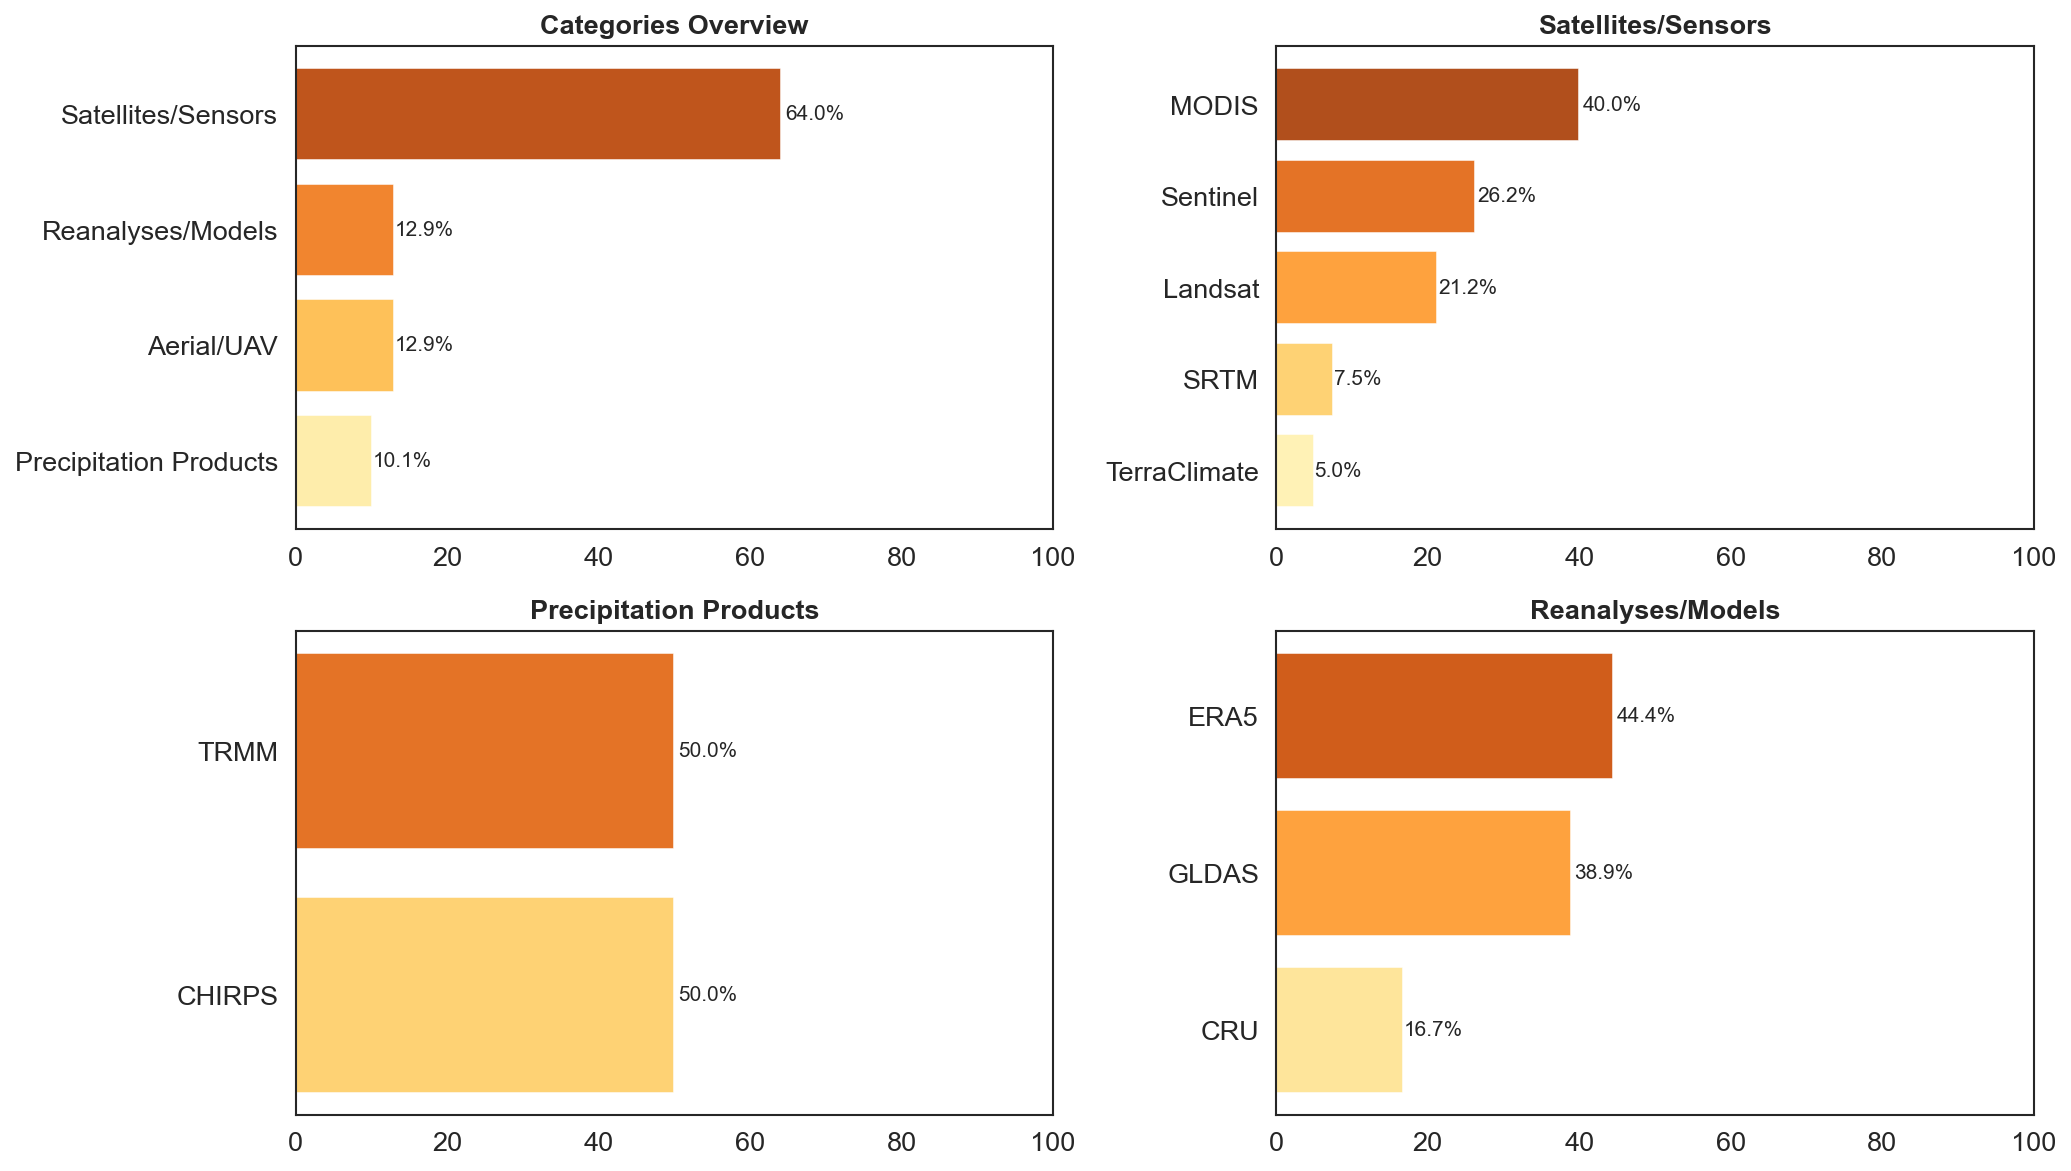

Figura salva: figures/temporal_evolution_categorized.pdf
Figura salva: figures/stackedbar_architecture_droughtindex_pct.pdf
Figura salva: figures/tasktype_by_architecture_stack_pct.pdf
Figura salva: figures/wordcloud_titles.pdf
Figura salva: figures/most_used_journals_bar_chart.pdf


C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categor

Figura salva: figures/scatter_LTmin_LTmax_DataSize.pdf


In [6]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
from wordcloud import WordCloud
from matplotlib.colors import ListedColormap

# ============================================================
# CONFIGURAÇÕES GLOBAIS
# ============================================================
# Configurações de estilo
BG = "white"  # Background color
TXT = "black"  # Text color

# Configurações de fonte
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 13
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["xtick.labelsize"] = 13
plt.rcParams["ytick.labelsize"] = 13
plt.rcParams["legend.fontsize"] = 12
plt.rcParams["figure.titlesize"] = 14

# Caminhos dos arquivos
FILE_PATH = "data/data_extraction.xlsx"
SHEET_NAMES = {
    "main": 0,
    "info": "Sheet2", 
    "arch": "Sheet3",
    "lead_time": "Sheet4"
}

# ============================================================
# FUNÇÕES UTILITÁRIAS
# ============================================================
def savefig_pdf(fig, filename, folder="figures", dpi=300):
    """Save matplotlib figure as high-resolution PDF"""
    os.makedirs(folder, exist_ok=True)
    path = f"{folder}/{filename}.pdf"
    fig.savefig(path, dpi=dpi, bbox_inches='tight', pad_inches=0.1, transparent=True)
    plt.close(fig)
    print(f"Figura salva: {path}")

def split_and_explode(df, column, sep=";"):
    """Split semicolons preserving NaN"""
    out = df.copy()
    out[column] = out[column].fillna("").astype(str).str.split(sep)
    out = out.explode(column)
    out[column] = out[column].str.strip()
    out = out[out[column] != ""]
    return out

# ============================================================
# NORMALIZAÇÃO DE SENSORES
# ============================================================
_CANONICAL = {
    "landsat":"Landsat","landsat 8":"Landsat","landsat-8":"Landsat",
    "landsat tm":"Landsat","landsat etm+":"Landsat","oli":"Landsat","tirs":"Landsat",
    "modis":"MODIS","viirs":"VIIRS",
    "avhrr":"AVHRR (GIMMS)","gimms":"AVHRR (GIMMS)","gimms ndvi":"AVHRR (GIMMS)",
    "sentinel":"Sentinel","sentinel-1":"Sentinel","sentinel-2":"Sentinel","msi":"Sentinel",
    "planetscope":"PlanetScope","naip":"NAIP",
    "fy-4a":"FY-4A","gf-2":"GaoFen-2","gaofen":"GaoFen",
    "srtm":"SRTM","aster":"ASTER-GDEM","aster-gdem":"ASTER-GDEM",
    "sar":"SAR","palsar":"PALSAR",
    "smap":"SMAP","smos":"SMOS","amsr2":"AMSR2","grace":"GRACE",
    "trmm":"TRMM","imerg":"IMERG","cmorph":"CMORPH","gsmap":"GSMaP",
    "persiann-cdr":"PERSIANN-CDR","persiann":"PERSIANN","chirps":"CHIRPS",
    "era5":"ERA5","gldas":"GLDAS","fldas":"FLDAS","nldas":"NLDAS","nldas-2":"NLDAS-2",
    "cldas":"CLDAS","silo":"SILO","noaa":"NOAA","cru":"CRU",
    "esa cci":"ESA-CCI","glass":"GLASS","ealco":"EALCO","cpc":"CPC","esri":"ESRI",
    "etopo":"ETOPO","etopo1":"ETOPO",
    "uav":"Aerial/UAV","rgb camera":"Aerial/UAV","camera":"Aerial/UAV","lidar":"Aerial/UAV",
    "aerial camera":"Aerial/UAV","hyperspectral":"Aerial/UAV","aerial / uav":"Aerial/UAV",
}

_DROP = {"n/i","ni","n.a.","na",""}

def _normalize_token(s):
    t = s.strip().lower()
    return _CANONICAL.get(t, s.strip())

def _split_sensors(cell):
    if pd.isna(cell):
        return []
    parts = [p.strip() for p in str(cell).replace("、",";").split(";")]
    return [_normalize_token(p) for p in parts if p and p.lower() not in _DROP]

# ============================================================
# CATEGORIZAÇÃO
# ============================================================
_CATEGORY_RULES = {
    "Satellites/Sensors": {"Landsat","MODIS","VIIRS","AVHRR (GIMMS)","Sentinel","PlanetScope",
                          "FY-4A","GaoFen-2","GaoFen","SRTM","ASTER-GDEM","SAR","PALSAR",
                          "SMAP","SMOS","AMSR2","GRACE","NAIP"},
    "Precipitation Products": {"TRMM","IMERG","CMORPH","GSMaP","PERSIANN-CDR","PERSIANN","CHIRPS"},
    "Reanalyses/Models": {"ERA5","GLDAS","FLDAS","NLDAS","NLDAS-2","CLDAS","SILO","NOAA","CRU",
                         "ESA-CCI","GLASS","EALCO","CPC"},
    "DEM/Topography": {"ETOPO"},
    "Aerial/UAV": {"Aerial/UAV", "Camera"},
    "Other Datasets/Providers": {"ESRI"},
}

def categorize_source(name):
    for cat, items in _CATEGORY_RULES.items():
        if name in items:
            return cat
    up = name.upper()
    if any(k in up for k in ["ERA","GLDAS","NLDAS","FLDAS","CCI","CRU","GLASS","EALCO","SILO","CPC"]):
        return "Reanalyses/Models"
    if any(k in up for k in ["TRMM","IMERG","CMORPH","GSMAP","PERSIANN","CHIRPS"]):
        return "Precipitation Products"
    if any(k in up for k in ["UAV","CAMERA","LIDAR","HYPERSPECTRAL","AERIAL"]):
        return "Aerial/UAV"
    if any(k in up for k in ["ETOPO","SRTM","ASTER"]):
        return "DEM/Topography"
    if "ESRI" in up:
        return "Other Datasets/Providers"
    return "Satellites/Sensors"

# ============================================================
# ANÁLISE DE SENSORES
# ============================================================
def analyze_sensor_frequencies(path, sheet_index=0, threshold=2):
    df = pd.read_excel(path, sheet_name=sheet_index)
    if "Sensor" not in df.columns:
        return pd.DataFrame(columns=["Sensor","Frequency","Category"])

    all_tokens = []
    for tokens in df["Sensor"].apply(_split_sensors):
        all_tokens.extend(tokens)

    counts = pd.Series(all_tokens).value_counts()
    frequent = counts[counts > threshold]

    out = pd.DataFrame({"Sensor": frequent.index, "Frequency": frequent.values})
    out["Category"] = out["Sensor"].apply(categorize_source)
    return out

def analyze_category_frequencies(df_analysis):
    if df_analysis.empty:
        return pd.DataFrame(columns=["Category","Frequency"])
    grp = df_analysis.groupby("Category", as_index=False)["Frequency"].sum()
    return grp.sort_values("Frequency", ascending=False)

# ============================================================
# PLOT COMBINADO (SENSORES E CATEGORIAS)
# ============================================================
def plot_combined(df_analysis, df_cat, top_n=5, path_out="figures/panel_combined.pdf"):
    df = df_analysis[df_analysis["Category"]!="Aerial/UAV"].copy()
    df = df[df["Sensor"].str.startswith("Others")==False]
    df["rank"] = df.groupby("Category")["Frequency"].rank(method="first", ascending=False)
    df = df[df["rank"]<=top_n].sort_values(["Category","Frequency"], ascending=[True,False])

    cats_all = df["Category"].unique().tolist()
    ordered_cats = []
    if "Satellites/Sensors" in cats_all:
        ordered_cats.append("Satellites/Sensors")
    for c in cats_all:
        if c!="Satellites/Sensors":
            ordered_cats.append(c)
    cats = ["Categories Overview"] + ordered_cats

    n_c = len(cats)
    ncols = 2
    nrows = int(np.ceil(n_c/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4*nrows), squeeze=False)

    for i, cat in enumerate(cats):
        ax = axes[i//ncols, i%ncols]
        if cat == "Categories Overview":
            dfc = df_cat.copy().sort_values("Frequency", ascending=True)
            total = dfc["Frequency"].sum()
            dfc["Pct"] = dfc["Frequency"]/total*100
            palette = sns.color_palette("YlOrBr", n_colors=len(dfc))
            bars = ax.barh(dfc["Category"], dfc["Pct"], color=palette, edgecolor="white", alpha=0.9)
            ax.set_title("Categories Overview", fontsize=13, fontweight="bold")
            ax.set_xlim(0,100)
            for b, v in zip(bars, dfc["Pct"]):
                ax.text(b.get_width()*1.01, b.get_y()+b.get_height()/2, f"{v:.1f}%",
                        va="center", ha="left", fontsize=10)
        else:
            sub = df[df["Category"]==cat].sort_values("Frequency", ascending=True)
            total_cat = sub["Frequency"].sum()
            sub["Pct"] = sub["Frequency"]/total_cat*100 if total_cat>0 else 0
            palette = sns.color_palette("YlOrBr", n_colors=len(sub))
            bars = ax.barh(sub["Sensor"], sub["Pct"], color=palette, edgecolor="white", alpha=0.9)
            ax.set_title(cat, fontsize=13, fontweight="bold")
            ax.set_xlim(0,100)
            for b, v in zip(bars, sub["Pct"]):
                ax.text(b.get_width()*1.01, b.get_y()+b.get_height()/2, f"{v:.1f}%",
                        va="center", ha="left", fontsize=10)

    for j in range(i+1, nrows*ncols):
        axes[j//ncols, j%ncols].axis("off")

    plt.tight_layout()
    os.makedirs(os.path.dirname(path_out), exist_ok=True)
    plt.savefig(path_out, dpi=300, bbox_inches="tight")
    plt.savefig(path_out.replace(".pdf",".png"), dpi=300, bbox_inches="tight")
    plt.show()

# ============================================================
# ARQUITETURAS DE DEEP LEARNING
# ============================================================
ARCH_MAP = {
    "CNN": "CNN", "1D CNN": "CNN", "1DCNN": "CNN", "3D-CNN": "CNN", "Conv2D": "CNN",
    "U-Net": "CNN", "UNet": "CNN", "EfficientUNet": "CNN", "ResUNet": "CNN",
    "ResUNet++": "CNN", "ResNet": "CNN", "VGG": "CNN", "FCN": "CNN", "DeepLabv3": "CNN",
    "DeepWaterMap": "CNN", "BCDU-Net": "CNN", "YOLO": "CNN", "SharpMask": "CNN",
    "EfficientNet": "CNN", "DenseNet": "CNN", "SegNet": "CNN", "AlexNet": "CNN",
    "GoogLeNet": "CNN", "Inception": "CNN", "MobileNet": "CNN",
    "RNN": "RNN", "LSTM": "RNN", "BiLSTM": "RNN", "Bi-LSTM": "RNN", "GRU": "RNN",
    "Bi-GRU": "RNN", "ConvLSTM": "RNN", "Seq2Seq": "RNN",
    "Transformer": "Transformer", "Informer": "Transformer", "TFT": "Transformer",
    "ViT": "Transformer", "SAM": "Transformer",
    "MLP": "DFNN", "DFNN": "DFNN", "MLF": "DFNN", "EEDNN": "DFNN",
    "AE": "Autoencoder", "DCAE": "Autoencoder", "VAE": "Autoencoder",
    "β-VAE": "Autoencoder", "CVAE": "Autoencoder", "VQ-VAE": "Autoencoder",
    "GAN": "GAN", "cGAN": "GAN"
}

FAMILY_ORDER = ["Transformer", "GAN", "CNN", "DFNN", "Autoencoder", "RNN"]
FAMILY_COLORS = {
    "CNN": "#FF7F0E", "RNN": "#1F77B4", "Transformer": "#2CA02C",
    "DFNN": "#D62728", "Autoencoder": "#9467BD", "GAN": "#8C564B"
}
LINESTYLES = {
    "CNN": "-", "RNN": "--", "Transformer": "-.", "DFNN": ":",
    "Autoencoder": (0, (3, 1, 1, 1)), "GAN": (0, (5, 2))
}

def _is_unet(token):
    return "unet" in token.lower().replace("-", "")

def _map_architectures(token):
    if not token or str(token).strip() in {"", "N/I"}:
        return []
    if _is_unet(token):
        return ["CNN"]
    if token in ARCH_MAP:
        return [ARCH_MAP[token]]
    for key, fam in ARCH_MAP.items():
        if key.lower() in token.lower():
            return [fam]
    return []

def process_row_architectures(dl_arch, dl_model):
    families = set()
    for source in (dl_arch, dl_model):
        if pd.isna(source) or str(source).strip() in {"", "N/I"}:
            continue
        for token in str(source).split(";"):
            families.update(_map_architectures(token.strip()))
    return sorted(families)

def build_pivot_by_family(df_merged, year_col="Year"):
    df = df_merged.copy()
    df = df.dropna(subset=[year_col])
    df[year_col] = df[year_col].astype(int)
    df["Families"] = df.apply(lambda r: process_row_architectures(r.get("DL_Architecture"), r.get("DL_Model")), axis=1)

    expanded = []
    for _, r in df.iterrows():
        for fam in r["Families"]:
            expanded.append({"Year": r[year_col], "Family": fam})
    if not expanded:
        return pd.DataFrame(columns=FAMILY_ORDER)

    df_exp = pd.DataFrame(expanded)
    pivot = df_exp.pivot_table(index="Year", columns="Family", aggfunc="size", fill_value=0)
    years = range(int(df_exp["Year"].min()), int(df_exp["Year"].max()) + 1)
    pivot = pivot.reindex(years, fill_value=0)

    for fam in FAMILY_ORDER:
        if fam not in pivot.columns:
            pivot[fam] = 0
    return pivot[FAMILY_ORDER]

# ============================================================
# GRÁFICOS DE ARQUITETURAS DL
# ============================================================
def plot_family_trends(pivot):
    fig, ax = plt.subplots(figsize=(14, 7), facecolor=BG)
    ax.set_facecolor(BG)

    for fam in FAMILY_ORDER:
        if fam not in pivot.columns:
            continue
        series = pivot[fam]
        if (series > 0).any():
            idx_nonzero = series[series > 0].index
            ax.plot(pivot.index, series.values, linewidth=2.2, color=FAMILY_COLORS[fam],
                   linestyle=LINESTYLES.get(fam, "-"), label=fam)
            ax.plot(idx_nonzero, series.loc[idx_nonzero].values, marker="o", markersize=6,
                   linestyle="None", color=FAMILY_COLORS[fam])

    ax.set_xlabel("Year", color=TXT)
    ax.set_ylabel("Frequency", color=TXT)
    ax.set_xticks(pivot.index)
    ax.set_xlim(pivot.index.min() - 0.5, pivot.index.max() + 0.5)

    ymax = int(pivot.values.max()) if pivot.size else 0
    ax.set_ylim(0, ymax + max(1, int(0.1 * max(1, ymax))))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    ax.grid(True, axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.4)
    ax.set_axisbelow(True)

    for fam in FAMILY_ORDER:
        if fam in pivot.columns:
            for year, val in zip(pivot.index, pivot[fam].values):
                if val > 0:
                    ax.annotate(f"{int(val)}", (year, val), textcoords="offset points",
                               xytext=(0, 8), ha="center", fontsize=12, color=TXT)

    handles = [Patch(facecolor=FAMILY_COLORS[f], edgecolor="black", label=f) for f in FAMILY_ORDER if f in pivot.columns]
    ax.legend(handles=handles, loc="upper left", frameon=True, facecolor="white", framealpha=0.9,
             edgecolor="none", ncol=1, title="DL Architectures", title_fontsize=13)

    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_linewidth(0.8)
        ax.spines[s].set_color("#999999")

    fig.tight_layout()
    return fig

# ============================================================
# GRÁFICO DE BARRAS EMPILHADAS
# ============================================================
def plot_arch_x_droughtindex_pct(table_pct):
    colors = sns.color_palette("YlOrBr", n_colors=len(table_pct.columns))
    fig, ax = plt.subplots(figsize=(12, 6), facecolor=BG)
    ax.set_facecolor(BG)

    x = np.arange(len(table_pct.index))
    bottom = np.zeros(len(table_pct))
    for i, col in enumerate(table_pct.columns):
        vals = table_pct[col].values
        ax.bar(x, vals, bottom=bottom, label=col, color=colors[i], edgecolor="white", linewidth=0.5)
        bottom += vals

    ax.set_xticks(x, table_pct.index, rotation=0)
    ax.set_ylabel("Frequency (%)", color=TXT)
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", linestyle=":", linewidth=0.8, alpha=0.4, color="gray")
    ax.set_axisbelow(True)

    ax.legend(title="Drought index", loc="lower right", frameon=True, facecolor="white",
             framealpha=0.85, edgecolor="none", ncol=1, title_fontsize=12)

    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_linewidth(0.8)
        ax.spines[s].set_color("#999999")

    fig.tight_layout()
    return fig

def plot_arch_x_tasktype_pct(tab_pct):
    colors = sns.color_palette("YlOrBr", n_colors=len(tab_pct.columns))
    fig, ax = plt.subplots(figsize=(12, 6), facecolor=BG)
    ax.set_facecolor(BG)

    x = np.arange(len(tab_pct.index))
    bottom = np.zeros(len(tab_pct))
    for i, col in enumerate(tab_pct.columns):
        vals = (tab_pct[col].values * 100.0)
        ax.bar(x, vals, bottom=bottom, label=col, color=colors[i], edgecolor="white", linewidth=0.5)
        bottom += vals

    ax.set_xticks(x, tab_pct.index, rotation=0)
    ax.set_ylabel("Frequency (%)", color=TXT)
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", linestyle=":", linewidth=0.8, alpha=0.4, color="gray")
    ax.set_axisbelow(True)

    ax.legend(title="Task type", loc="lower right", frameon=True, facecolor="white",
             framealpha=0.85, edgecolor="none", ncol=1, title_fontsize=12)

    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_linewidth(0.8)
        ax.spines[s].set_color("#999999")

    fig.tight_layout()
    return fig

# ============================================================
# WORD CLOUD
# ============================================================
def generate_wordcloud_from_titles(df, title_col="Title", stopwords=None):
    if stopwords is None:
        stopwords = ['in', 'or', 'and', 'for', 'from', 'using', 'new', 'with',
                    'the', 'a', 'by', 'at', 'to', 'on', 'based', 'four', 'mu',
                    'tea', 'us', 'of', 'an', 'via']

    all_titles = " ".join(df[title_col].dropna().astype(str))
    tokens = all_titles.split()
    cleaned = " ".join([word.lower() for word in tokens if word.lower() not in stopwords and re.match("^[a-zA-Z]+$", word)])

    family_colors = list(FAMILY_COLORS.values())
    custom_cmap = ListedColormap(family_colors)

    wordcloud = WordCloud(width=1800, height=800, background_color="white", colormap=custom_cmap,
                         min_font_size=10, max_words=200, random_state=42).generate(cleaned)

    fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(wordcloud, interpolation="bilinear")
    ax.axis("off")
    return fig

# ============================================================
# ANÁLISE DE JORNAIS
# ============================================================
def analyze_journal_frequencies(path, sheet_index=0, threshold=3):
    df = pd.read_excel(path, sheet_name=sheet_index)
    if "Journal" not in df.columns:
        raise ValueError("Column 'Journal' not found")

    journal_counts = df["Journal"].value_counts(dropna=False)
    frequent = journal_counts[journal_counts >= threshold]
    others_count = journal_counts[journal_counts < threshold].sum()

    if others_count > 0:
        frequent = pd.concat([frequent, pd.Series({f"Others (<{threshold})": others_count})])

    df_analysis = pd.DataFrame({"Journal": frequent.index.astype(str), "Frequency": frequent.values})
    df_analysis = df_analysis[df_analysis["Journal"] != "IEEE Access"].reset_index(drop=True)
    return df_analysis

def plot_journal_bar_chart(df_analysis):
    abbreviations = {
        "International Journal of Applied Earth Observation and Geoinformation": "Int. J. Appl. Earth Obs. & Geoinfo.",
        "Remote Sensing of Environment": "Remote Sens. Environ.",
        "Journal of Hydrology": "J. Hydrol.",
        "Earth Science Informatics": "Earth Sci. Informatics",
        "Remote Sensing Applications: Society and Environment": "Remote Sens. Appl.: Soc. & Environ.",
        "IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing": "IEEE J. Sel. Top. Appl. Earth Obs. Remote Sens.",
    }

    df_plot = df_analysis.copy()
    df_plot["Journal"] = df_plot["Journal"].map(lambda x: abbreviations.get(x, x))
    df_plot["is_others"] = df_plot["Journal"].str.startswith("Others")
    df_plot = df_plot.sort_values(by=["is_others", "Frequency"], ascending=[True, True]).drop(columns="is_others")

    n_colors = len(df_plot)
    palette = sns.color_palette("YlOrBr_r", n_colors=n_colors)
    
    if any(df_plot["Journal"].str.startswith("Others")):
        others_index = df_plot[df_plot["Journal"].str.startswith("Others")].index[0]
        if len(palette) > others_index:
            palette[others_index] = '#543005'

    fig, ax = plt.subplots(figsize=(11, 6), facecolor=BG)
    ax.set_facecolor(BG)

    bars = ax.barh(df_plot["Journal"], df_plot["Frequency"], color=palette, edgecolor="white", 
                  linewidth=1.5, height=0.7, alpha=0.9)

    ax.set_xlabel("Frequency", color=TXT)
    ax.set_ylabel("", color=TXT)
    ax.grid(True, axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.4)
    ax.grid(False, axis="x")

    total = float(df_plot["Frequency"].sum())
    labels = [f"{(freq / total) * 100:.1f}%" for freq in df_plot["Frequency"]]

    max_val = df_plot["Frequency"].max()
    pad = max_val * 0.02
    new_xlim = max_val * 1.12 + 1

    for bar, label in zip(bars, labels):
        x = bar.get_width()
        y = bar.get_y() + bar.get_height() / 2
        ax.text(x + pad, y, label, va="center", ha="left", fontsize=10, color="black")

    ax.set_xlim(0, new_xlim)

    for spine in ax.spines.values():
        spine.set_edgecolor("gray")
        spine.set_linewidth(1)

    return fig

# ============================================================
# EXECUÇÃO PRINCIPAL
# ============================================================
if __name__ == "__main__":
    # Análise de sensores
    df_analysis = analyze_sensor_frequencies(FILE_PATH, sheet_index=SHEET_NAMES["info"], threshold=2)
    df_cat = analyze_category_frequencies(df_analysis)
    
    if not df_analysis.empty:
        plot_combined(df_analysis, df_cat, top_n=5, path_out="figures/topN_per_category.pdf")
    
    # Análise de arquiteturas DL
    df_main = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAMES["main"])[["ID", "Year"]]
    df_arch = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAMES["arch"])
    df_merged = df_arch.merge(df_main, on="ID", how="left")
    
    # Fig 9 - Evolução temporal por família
    pivot_fam = build_pivot_by_family(df_merged, year_col="Year")
    fig9 = plot_family_trends(pivot_fam)
    savefig_pdf(fig9, "temporal_evolution_categorized")
    
    # Fig 12 e 13 - Arquitetura vs Índice de Seca e Tipo de Tarefa
    VALID_ARCH = ["CNN", "RNN", "Transformer", "DFNN", "GAN"]
    THRESHOLD = 3
    
    # Preparação dados Fig 12
    arch_exploded = split_and_explode(df_arch, "DL_Architecture")
    arch_exploded = arch_exploded[arch_exploded["DL_Architecture"].isin(VALID_ARCH)]
    
    df_info = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAMES["info"])
    index_exploded = split_and_explode(df_info, "Drought_Index")
    
    merged_arch_index = arch_exploded.merge(index_exploded[["ID", "Drought_Index"]], on="ID", how="inner")
    table_counts_12 = merged_arch_index.groupby(["DL_Architecture", "Drought_Index"]).size().unstack(fill_value=0)
    keep_cols_12 = table_counts_12.sum(axis=0) > THRESHOLD
    table_counts_12 = table_counts_12.loc[:, keep_cols_12]
    table_counts_12 = table_counts_12.loc[table_counts_12.sum(axis=1) > 0]
    table_pct = table_counts_12.div(table_counts_12.sum(axis=1), axis=0) * 100
    
    fig12 = plot_arch_x_droughtindex_pct(table_pct)
    savefig_pdf(fig12, "stackedbar_architecture_droughtindex_pct")
    
    # Preparação dados Fig 13
    task_exploded = split_and_explode(df_info[["ID", "Task_Type"]], "Task_Type")
    arch_exploded_13 = split_and_explode(df_arch, "DL_Architecture")
    arch_exploded_13 = arch_exploded_13[arch_exploded_13["DL_Architecture"].isin(VALID_ARCH)]
    
    merged_arch_task = arch_exploded_13.merge(task_exploded, on="ID", how="inner")
    tab_counts_13 = merged_arch_task.groupby(["DL_Architecture", "Task_Type"]).size().unstack(fill_value=0)
    tab_counts_13 = tab_counts_13.loc[tab_counts_13.sum(axis=1) > THRESHOLD]
    tab_pct = tab_counts_13.div(tab_counts_13.sum(axis=1), axis=0)
    
    fig13 = plot_arch_x_tasktype_pct(tab_pct)
    savefig_pdf(fig13, "tasktype_by_architecture_stack_pct")
    
    # Word Cloud
    df_titles = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAMES["main"])
    fig_wc = generate_wordcloud_from_titles(df_titles, title_col="Title")
    savefig_pdf(fig_wc, "wordcloud_titles")
    
    # Análise de jornais
    df_analysis_journal = analyze_journal_frequencies(FILE_PATH, sheet_index=SHEET_NAMES["main"], threshold=3)
    fig_journals = plot_journal_bar_chart(df_analysis_journal)
    savefig_pdf(fig_journals, "most_used_journals_bar_chart")
    
    # Scatter plot Lead Time
    df_lead = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAMES["lead_time"])
    df_lead = df_lead.rename(columns=lambda x: x.strip().lower())
    df_lead = df_lead.dropna(subset=['lt_min', 'lt_max', 'tr'])
    
    plt.figure(figsize=(10, 6))
    ax = sns.scatterplot(x='lt_min', y='lt_max', hue='tr', size='tr', sizes=(30, 200), 
                        palette='YlOrBr', data=df_lead, alpha=0.8, edgecolor="k", linewidth=0.5)
    ax.yaxis.grid(True, linestyle=':', linewidth=0.7, color='lightgray')
    ax.xaxis.grid(False)
    plt.xlabel("Min. Lead Time (days)", fontsize=14)
    plt.ylabel("Max. Lead Time (days)", fontsize=14)
    plt.legend(title_fontsize=12, fontsize=11, loc='best', frameon=True)
    
    for spine in ax.spines.values():
        spine.set_edgecolor('gray')
        spine.set_linewidth(1)
    
    savefig_pdf(plt.gcf(), "scatter_LTmin_LTmax_DataSize")
    plt.show()